ATIVIDADE DE OTIMIZAÇÃO - Q2

In [11]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import random
import math

In [12]:
# Função a ser maximizada:

LIMITES = [-1, 2]

def func(x):
    return x * np.sin(10 * np.pi * x) + 1

<function matplotlib.pyplot.show(close=None, block=None)>

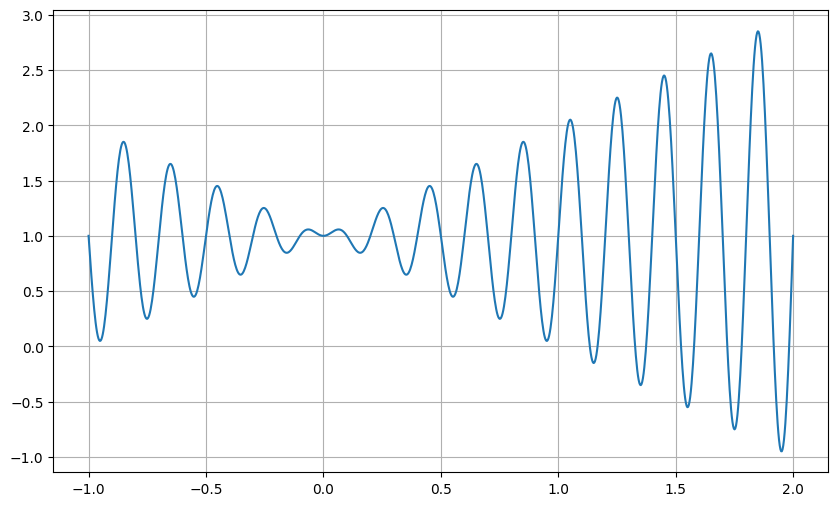

In [13]:
# Plotando função

x = np.linspace(LIMITES[0], LIMITES[1], 1000)
y = func(x)

plt.figure(figsize=(10, 6))
plt.plot(x, y)
plt.grid(True)
plt.show

A função possui uma variedade muito grande de valores. Apresenta muitos pontos máximos e mínimos locais, o que dificulta bastante a análise.
Por esse motivo, optei por seguir com o SA e refinar o valor com o HC.

In [ ]:
# Maximizando

def melhor_vizinho(x_atual):
    x0 = x_atual - 0.01
    x1 = x_atual + 0.01

    y0 = func(x0)
    y1 = func(x1)

    if y0 > y1:
        return [x0, y0]
    else:
        return [x1, y1]

def HillClimbing(x_init):
    x_atual = x_init
    y_atual = func(x_init)

    while True:
        vizinho = melhor_vizinho(x_atual)

        if vizinho[1] <= y_atual:
            return x_atual

        x_atual = vizinho[0]
        y_atual = vizinho[1]

def verifica_restricoes(sol):
    if LIMITES[0] <= sol <= LIMITES[1]:
        return True

    return False

def vizinho_aleatorio(sol):
    while True:
        nova = sol

        delta = random.uniform(LIMITES[0], LIMITES[1])

        nova += delta

        if verifica_restricoes(nova):
            return nova

def simulated_annealing():
    atual = (0)
    melhor = atual

    T = 100.0 # Temperatura inicial
    T_min = 0.5 # Temperatura mínima
    alpha = 0.95 # Taxa de resfriamento (cooling rate)

    while T > T_min:
        candidato = vizinho_aleatorio(atual)

        delta = func(candidato) - func(atual)

        if delta > 0:
            atual = candidato
        else:
            prob = math.exp(delta / T)

            if random.random() < prob:
                atual = candidato

        if func(atual) > func(melhor):
            melhor = atual

        T *= alpha

    return melhor

melhor = simulated_annealing()
print(HillClimbing(melhor))

1.8515726948713742
